# Challenge 1: The banknote-authentication data set problem

We will perform a nearly realistic analysis of the data set bank note authentication that can be downloaded from this [link](https://archive.ics.uci.edu/dataset/267/banknote+authentication) or from the [github repo](https://github.com/LorenzoTonet/Intro_to_ML_26-27/blob/main/data/data_banknote_authentication.txt)

## Data set description

Data were extracted from images that were taken from genuine and forged banknote-like specimens. For digitization, an industrial camera usually used for print inspection was used. The final images have 400x 400 pixels. Due to the object lens and distance to the investigated object gray-scale pictures with a resolution of about 660 dpi were gained. Wavelet Transform tool were used to extract features from images.
These features are:
1. variance of Wavelet Transformed image (continuous) 
2. skewness of Wavelet Transformed image (continuous) 
3. curtosis of Wavelet Transformed image (continuous) 
4. entropy of image (continuous) 
5. class (integer)

## Task description
We have a binary classification problem. The assignment can be divided in several parts:
    
    1. Load the data and pretreatment.
    2. Data exploring by Unsupervised Learning techniques.
    3. Construction of several models of Supervised Learning.
    4. Assessment and evaluation

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk

path_csv = "../data/data_banknote_authentication.csv"
column_names = ["variance", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv(path_csv, header=None, names=column_names)


### 1. Data pretreatment

Load the data and look at it: It is needed some kind of scaling? Why? Are the data points sorted in the original data set? Can it generate problems? How can this be solved?

In [5]:

df.head()



,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [16]:
feature_columns = column_names[:-1]

assert df.shape[1] == len(column_names)
assert df[feature_columns].notna().all().all()
assert df["class"].isin([0, 1]).all()

print(f"Shape: {df.shape}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print("Class distribution:")
print(df["class"].value_counts().sort_index())
print("Feature summary:")
print(f"Feature types: {df[feature_columns].dtypes.to_dict()}")

display(df[feature_columns].describe().T)


df_clean = df.drop_duplicates().reset_index(drop=True)

print(f"Rows after removing duplicates: {len(df_clean)}")
print(f"Duplicate rows: {df_clean.duplicated().sum()}")




Shape: (1348, 5)
Duplicate rows: 0
Class distribution:
class
0    738
1    610
Name: count, dtype: int64
Feature summary:
Feature types: {'variance': dtype('float64'), 'skewness': dtype('float64'), 'curtosis': dtype('float64'), 'entropy': dtype('float64')}


,count,mean,std,min,25%,50%,75%,max
variance,1348.0,0.445785,2.862906,-7.0421,-1.78665,0.518735,2.853250,6.8248
skewness,1348.0,1.909039,5.868600,-13.7731,-1.62700,2.334150,6.796025,12.9516
curtosis,1348.0,1.413578,4.328365,-5.2861,-1.54560,0.605495,3.199800,17.9274
entropy,1348.0,-1.168712,2.085877,-8.5482,-2.39310,-0.578890,0.403863,2.4495


Rows after removing duplicates: 1348
Duplicate rows: 0


In [17]:
features = df_clean[feature_columns]
q1 = features.quantile(0.25)
q3 = features.quantile(0.75)
iqr = q3 - q1
outlier_mask = features.lt(q1 - 1.5 * iqr) | features.gt(q3 + 1.5 * iqr)

print("Potential outliers by feature:")
print(outlier_mask.sum())
print(f"Rows with at least one potential outlier: {outlier_mask.any(axis=1).sum()}")


Potential outliers by feature:
variance     0
skewness     0
curtosis    59
entropy     32
dtype: int64
Rows with at least one potential outlier: 91


rimossi i duplicati, per evitare di avere una coppia nel train e una nel test set.

class_,0,1
variance,0,0
skewness,0,0
curtosis,0,59
entropy,15,17


class_,0,1
variance,0.00,0.00
skewness,0.00,0.00
curtosis,0.00,9.67
entropy,2.03,2.79


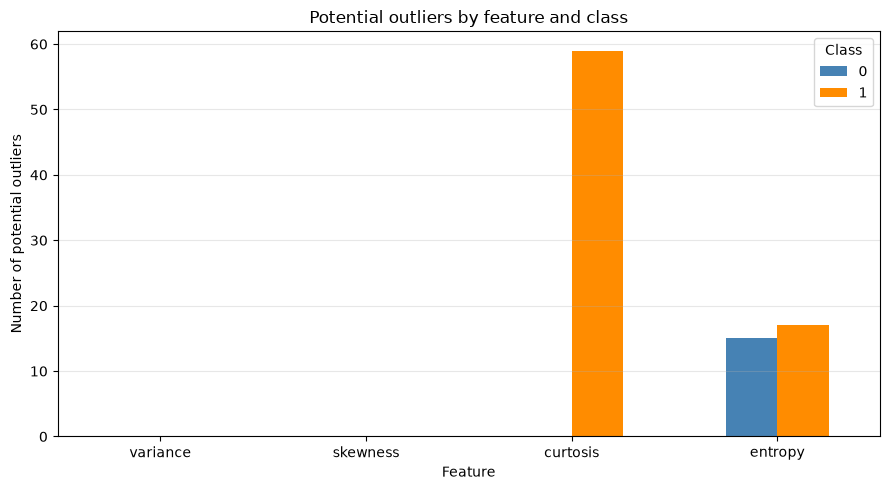

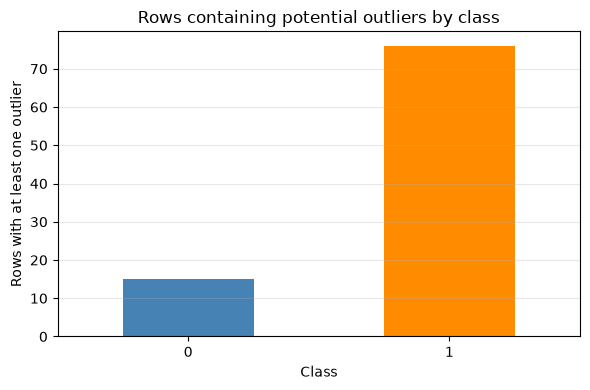

In [18]:
# Add class labels to the outlier mask
outliers_by_class = outlier_mask.assign(
    class_=df_clean["class"]
)
# Number of potential outliers by feature and class
outlier_counts = outliers_by_class.groupby("class_").sum().T
outlier_percent = (
    outliers_by_class.groupby("class_").mean().T.mul(100).round(2)
)

display(outlier_counts)
display(outlier_percent)

# Plot counts by class
outlier_counts.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "darkorange"],
)

plt.xlabel("Feature")
plt.ylabel("Number of potential outliers")
plt.title("Potential outliers by feature and class")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot rows with at least one potential outlier
row_outliers_by_class = (
    outlier_mask.any(axis=1)
    .groupby(df_clean["class"])
    .sum()
)

row_outliers_by_class.plot(
    kind="bar",
    figsize=(6, 4),
    color=["steelblue", "darkorange"],
)

plt.xlabel("Class")
plt.ylabel("Rows with at least one outlier")
plt.title("Rows containing potential outliers by class")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Gli outlier di curtosis sono presenti esclusivamente nella classe 1; pertanto non vengono rimossi automaticamente. La distribuzione suggerisce che possano essere caratteristiche informative delle banconote appartenenti a questa classe.

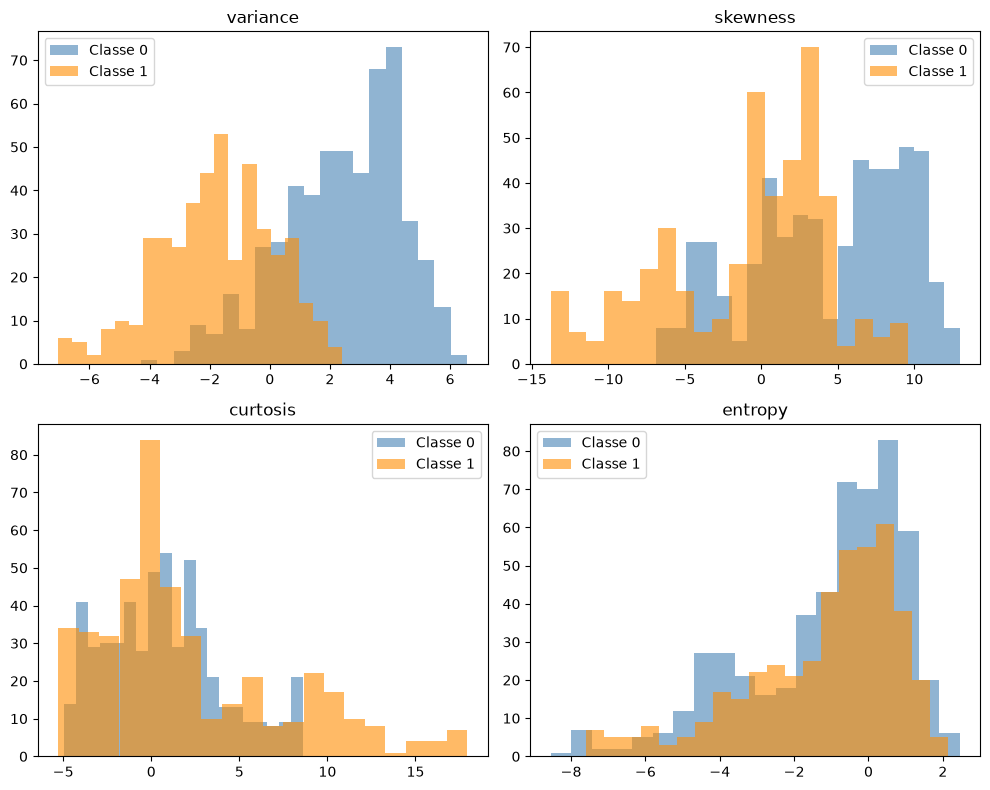

,variance,skewness,curtosis,entropy
variance,1.000000,0.292962,-0.392310,0.260520
skewness,0.292962,1.000000,-0.793138,-0.511532
curtosis,-0.392310,-0.793138,1.000000,0.313457
entropy,0.260520,-0.511532,0.313457,1.000000


In [23]:
from sklearn.model_selection import train_test_split
X = df_clean[feature_columns]
y = df_clean["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=372, stratify=y, shuffle=True, random_state=42)

X_train.describe()
X_train.skew()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

colors = {0: "steelblue", 1: "darkorange"}

for ax, feature in zip(axes.ravel(), feature_columns):
    for class_value, color in colors.items():
        ax.hist(
            X_train.loc[y_train == class_value, feature],
            bins=20,
            alpha=0.6,
            color=color,
            label=f"Classe {class_value}",
        )
    ax.set_title(feature)
    ax.legend()

plt.tight_layout()
plt.show()


X_train.corr()

La maggior parte delle feature presenta correlazioni basse o moderate. Tuttavia, skewness e curtosis mostrano una correlazione negativa forte (−0.785), mentre skewness ed entropy hanno una correlazione moderata (−0.521). Pertanto l’assunzione di indipendenza condizionale di Gaussian Naive Bayes è solo parzialmente rispettata e il modello potrebbe contare più volte informazione simile.  COntrolla Naive Bayes

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer

# Keep the target unchanged and transform only the skewed input features.
preprocessor = ColumnTransformer(
    [("power", PowerTransformer(method="yeo-johnson"), ["curtosis", "entropy"])],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocessor.fit(X_train)
X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

transformed_columns = feature_columns

X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=transformed_columns,
    index=X_train.index,
)

print("Skewness before transformation:")
print(X_train.skew().round(3))

print("Skewness after transformation:")
print(X_train_transformed_df.skew().round(3))


Skewness before transformation:
variance   -0.177
skewness   -0.437
curtosis    1.138
entropy    -1.042
dtype: float64
Skewness after transformation:
variance    0.052
skewness    0.018
curtosis   -0.177
entropy    -0.437
dtype: float64


che Yeo-Johnson deve stare dentro le pipeline dei modelli finali.

In [40]:
def accuracy(X, w, labels):
    """
    Parameters
    ----------
    X : array of dim n x d
        Matrix containing the dataset
    w : array of dim d
        Vector representing the coefficients of the logistic model
    labels : array of dim n
        Vector representing the ground truth label of each data point
    """
    a = labels - (2*np.round(sigmoidM(X,w))-1)
    acc = np.sum(a==0)/np.shape(X)[0]
    return acc

### 2. Unsupervised Learning

Use PCA and plot the two first components colouring according with the class. Are the classes linearly separable in this projection? What happens when I applied k-means with two classes in this space? And if I use all the coordinates? Try also t-SNE for projection and DBSCAN for the clustering and comment on the results.

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [35]:
class MyPCA:
    """PCA via eigendecomposition of the covariance matrix."""
    #TODO: Implement the PCA algorithm
    def __init__(self):
        self.mean_ = None
        self.scale_ = None
        self.components_ = None
        self.eigenvalues_ = None
        self.explained_variance_ratio_ = None


    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = None
        Xc = X - self.mean_
            
        C = Xc.T @ Xc / (X.shape[0] - 1)           # covariance matrix (unbiased)
        eigval, eigvec = np.linalg.eigh(C)         # eigh: symmetric matrix, ascending eigenvalues
        order = np.argsort(eigval)[::-1]           # sort by decreasing eigenvalue
        self.eigenvalues_ = eigval[order]
        self.components_ = eigvec[:, order]        # columns = principal directions
        self.explained_variance_ratio_ = self.eigenvalues_ / self.eigenvalues_.sum()
        return self

    def transform(self, X, k=None):
        Z = (X - self.mean_) @ self.components_
        return Z if k is None else Z[:, :k]

    def inverse_transform(self, Z):
        k = Z.shape[1]
        return Z @ self.components_[:, :k].T + self.mean_



Components needed for 95% variance: 3


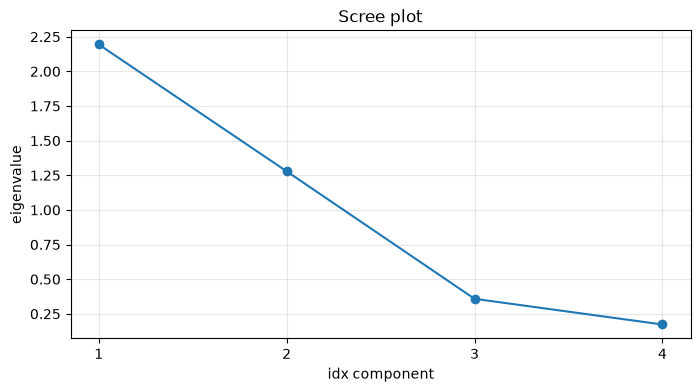

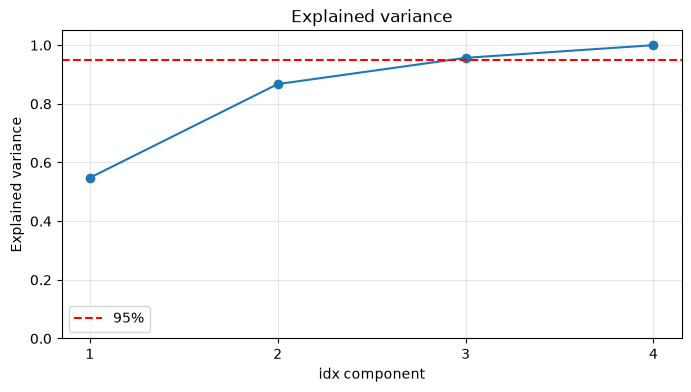

In [36]:
cumulative_var = np.cumsum(pca.explained_variance_ratio_)
threshold = 0.95

k = np.argmax(cumulative_var >= threshold) + 1

print(f"Components needed for {threshold:.0%} variance: {k}")



eigenvalues = pca.eigenvalues_
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

components = np.arange(1, len(eigenvalues) + 1)

plt.figure(figsize=(8, 4))
plt.plot(components, eigenvalues, marker="o")
plt.xlabel("idx component")
plt.ylabel("eigenvalue")
plt.title("Scree plot")
plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(components, cumulative_var, marker="o")
plt.axhline(y=threshold, linestyle="--", color="red", label="95%")
plt.xlabel("idx component")
plt.ylabel("Explained variance")
plt.title("Explained variance")
plt.ylim(0, 1.05)
plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

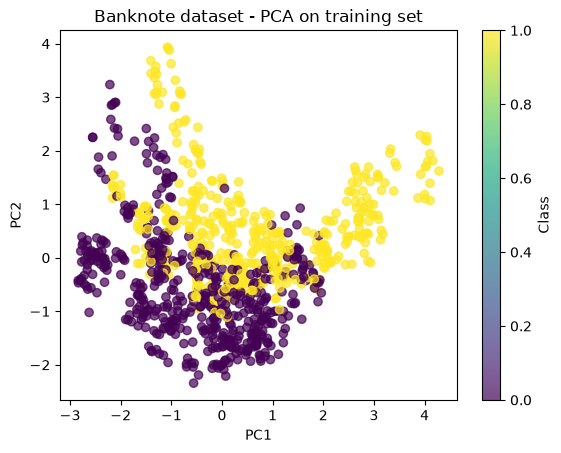

In [37]:
pca = MyPCA().fit(X_train_scaled)

X_train_pca = pca.transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Banknote dataset - PCA on training set")
plt.colorbar(label="Class")
plt.show()

Nella proiezione sulle prime due componenti principali, le classi mostrano una sovrapposizione significativa e non sembrano separabili perfettamente con una singola frontiera lineare. La PCA, essendo una trasformazione non supervisionata, massimizza la varianza e non necessariamente la separazione tra classi. Le componenti successive potrebbero contenere informazione discriminante non visibile nel piano PC1–PC2.



In [42]:
#klustering
def my_kmeans(X, k, max_iters=100, tol=1e-4):
    #TODO: Implement the K-means clustering algorithm
    """K-means clustering algorithm."""
    n_samples, n_features = X.shape

    labels = np.zeros(n_samples, dtype=int)
    # Randomly initialize centroids
    centroids_idx = np.random.choice(n_samples, size=k, replace=False)
    centroids = X[centroids_idx]
    new_centroids = np.zeros((k, n_features))
    
    for _ in range(max_iters):
        # Assign clusters based on closest centroid
        # Create a distance matrix to store distances from each sample to each centroid -> N x k
        distances = np.full((n_samples, k), np.inf)

        for i in range(k):
            for j in range(n_samples):
                distances[j, i] = np.linalg.norm(X[j] - centroids[i])

        # Assign labels based on the closest centroid
        for j in range(n_samples):
            labels[j] = np.argmin(distances[j, :])
        
        # Update centroids
        for i in range(k):
            cluster_points = X[labels == i]
            if len(cluster_points) > 0:
                new_centroids[i] = cluster_points.mean(axis=0)
            else:
                # If a cluster has no points assigned, reinitialize its centroid randomly
                new_centroids[i] = X[np.random.choice(n_samples)]
        
        # Check for convergence (if centroids do not change)
        if np.all(np.abs(centroids - new_centroids) < tol):
            break
        
        centroids = new_centroids
    
    return labels, centroids

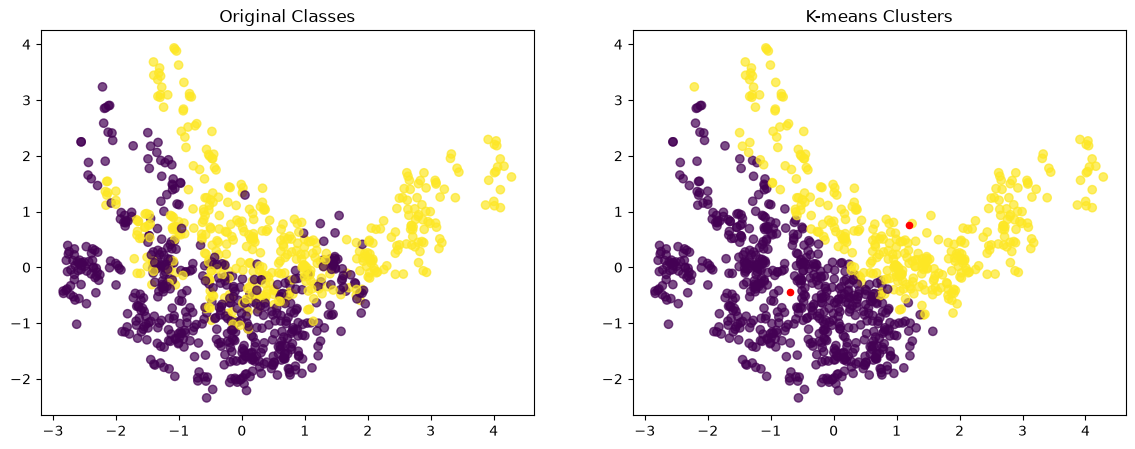

In [43]:

np.random.seed(42)
labels, centroids = my_kmeans(X_train_pca, k=2)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="viridis",
    alpha=0.7
)
ax[0].set_title("Original Classes")

ax[1].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=labels, cmap='viridis', alpha=0.7)
ax[1].set_title("K-means Clusters")
ax[1].scatter(centroids[:, 0], centroids[:, 1], c='red', marker='o', s=20, label='Centroids')

In [49]:
from sklearn.metrics import adjusted_rand_score,confusion_matrix,accuracy_score

ari = adjusted_rand_score(y_train, labels)
print(f"ARI: {ari:.3f}")


print(confusion_matrix(y_train, labels))


acc = max(
    accuracy_score(y_train, labels),
    accuracy_score(y_train, 1 - labels)
)
print(f"Best-matching accuracy: {acc:.3f}")

ARI: 0.345
[[476  58]
 [143 299]]
Best-matching accuracy: 0.794


What happens when I applied k-means with two classes in this space? 
K-means sulle prime due componenti identifica parzialmente la struttura delle classi. L’accuracy di corrispondenza è circa 79.4%, mentre l’ARI pari a 0.345 indica un accordo moderato. Pertanto le classi sono parzialmente separabili nello spazio PCA, ma i cluster presentano ancora una sovrapposizione significativa.

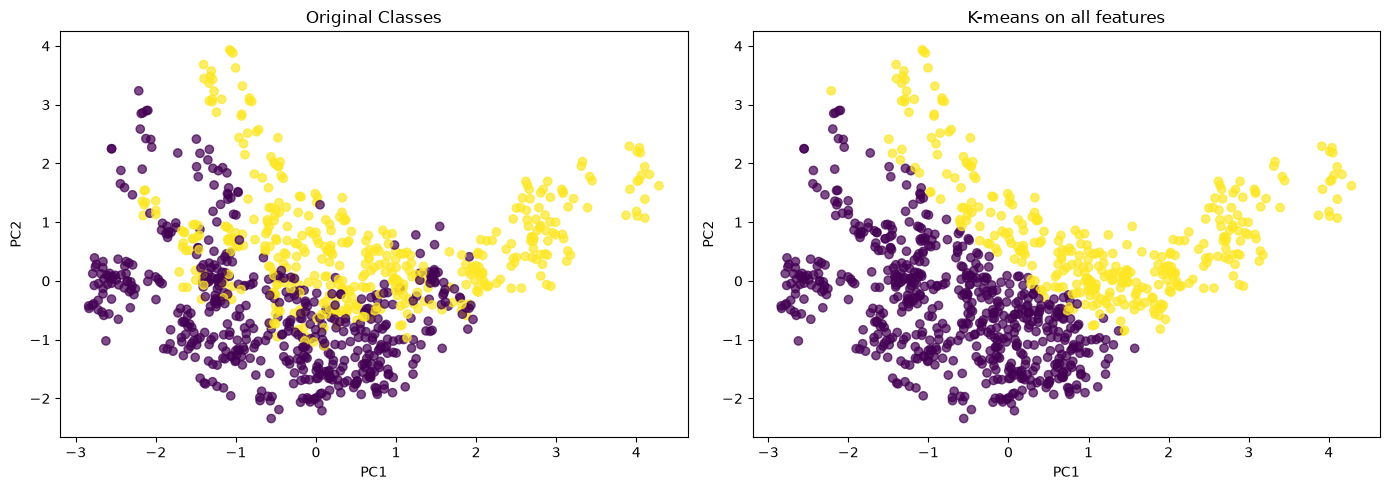

In [54]:
np.random.seed(42)
labels_all, centroids_all = my_kmeans(X_train_scaled, k=2)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="viridis",
    alpha=0.7,
)
ax[0].set_title("Original Classes")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

ax[1].scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=labels_all,
    cmap="viridis",
    alpha=0.7,
)
ax[1].set_title("K-means on all features")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [55]:
from sklearn.metrics import adjusted_rand_score,confusion_matrix,accuracy_score

ari = adjusted_rand_score(y_train, labels)
print(f"ARI: {ari:.3f}")


print(confusion_matrix(y_train, labels))


acc = max(
    accuracy_score(y_train, labels),
    accuracy_score(y_train, 1 - labels)
)
print(f"Best-matching accuracy: {acc:.3f}")

ARI: 0.345
[[476  58]
 [143 299]]
Best-matching accuracy: 0.794


Ottengo gli stessi risultati anche usando tutte le coordinate, con un’accuracy di corrispondenza di circa 79.4% e un ARI di 0.345. Questo suggerisce che la struttura dei cluster non è completamente catturata dalle prime due componenti principali, ma l’informazione discriminante non è sufficiente per una separazione netta delle classi.

### 3. Supervised Learning

Generate a subset of the data of 372 elements that would be saved as test set. With the rest of the data generate the following models: Logistic Regression, Decision tree (use the ID3 algorithm), Naive Bayes and k-NN. 

Investigate the effect of regularization (when possible) and use cross validation for setting the hyper-parameters when needed. 

Compare the performances in terms of accuracy, precision, recall and F1-score on the test set. Comment these results at the light of those obtained from the Unsupervised Learning analysis. Could you propose a way to improve these results?     


In [14]:
#generation of the subset of 372 elements from the original dataset
test_set = df.sample(n=372, random_state=42)
train_set = df.drop(test_set.index)


In [15]:
# this is a batched version to get logistic output for the whole matrix at the same time
def sigmoidM(X, w):
    """
    Parameters
    ----------
    X : array of dim n x d
        Matrix containing the dataset
    w : array of dim d
        Vector representing the coefficients of the logistic model
    """
    y = 1/(1 + np.exp(-np.matmul(X,w)))
    return y

def LogisticLoss(X, y, w):
    """
    Parameters
    ----------
    X : array of dim n x d
        Matrix containing the dataset
    y : array of dim n
        Vector representing the ground truth label of each data point
    w : array of dim d
        Vector representing the coefficients of the logistic model
    """
    cost = -y * (np.log(sigmoidM(X,w))) - (1 - y) * np.log(1 - sigmoidM(X,w))
    return cost


def GDLogistic(X, labels, iters, gamma, tol = 1e-3):
    """
    Parameters
    ----------
    X : array of dim n x d
        Matrix containing the dataset
    labels : array of dim n
        Vector representing the ground truth label of each data point
    iter : int
        Number of GD iterations
    gamma : float
        Learning rate
    """
    d = np.shape(X)  # d contains the shape of X, which is a tuple (n, d)
    cost = np.zeros(iters)  # Create an array to store the cost at each iteration
    w = np.random.uniform(0, 0.01, d[1])  # Initialize w with random values
    W = np.zeros((iters, 2))  # Create an array to store the weight vectors at each iteration
    n = X.shape[0]

    for i in range(iters):
        W[i] = w
        loss_vector = LogisticLoss(X, y, w)
        loss[i] = loss_vector
        w = w- gamma / n * (X.T @ (sigmoidM(X, w) - labels))
        if loss[i] < tol:
            break
    return W, loss
